In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [16]:
df = pd.read_excel("../data/netflix.xlsx", sheet_name="Training_Data")

df.head()

,Viewer_ID,Age_Group,Primary_Device,Recent_Genre,Average_Watch_Minutes,Completion_Rate,Action_Score,Comedy_Score,Drama_Score,Documentary_Score,Weekend_Viewer,Binge_Frequency,Recommended_Genre
0,V085,45+,Tablet,Drama,100,0.90,2,1,5,3,No,Medium,Drama
1,V076,18-24,Laptop,Comedy,55,0.93,2,5,1,2,Yes,High,Comedy
2,V004,35-44,Mobile,Action,106,0.69,4,1,3,3,Yes,Medium,Action
3,V092,25-34,Mobile,Drama,102,0.88,2,2,5,3,Yes,Medium,Drama
4,V090,35-44,Tablet,Drama,83,0.83,1,2,5,5,Yes,Medium,Drama


In [15]:
df.shape


(160, 13)

In [17]:
df.columns

Index(['Viewer_ID', 'Age_Group', 'Primary_Device', 'Recent_Genre',
       'Average_Watch_Minutes', 'Completion_Rate', 'Action_Score',
       'Comedy_Score', 'Drama_Score', 'Documentary_Score', 'Weekend_Viewer',
       'Binge_Frequency', 'Recommended_Genre'],
      dtype='str')

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Viewer_ID              160 non-null    str    
 1   Age_Group              160 non-null    str    
 2   Primary_Device         160 non-null    str    
 3   Recent_Genre           160 non-null    str    
 4   Average_Watch_Minutes  160 non-null    int64  
 5   Completion_Rate        160 non-null    float64
 6   Action_Score           160 non-null    int64  
 7   Comedy_Score           160 non-null    int64  
 8   Drama_Score            160 non-null    int64  
 9   Documentary_Score      160 non-null    int64  
 10  Weekend_Viewer         160 non-null    str    
 11  Binge_Frequency        160 non-null    str    
 12  Recommended_Genre      160 non-null    str    
dtypes: float64(1), int64(5), str(7)
memory usage: 16.4 KB


In [19]:
df.describe()

,Average_Watch_Minutes,Completion_Rate,Action_Score,Comedy_Score,Drama_Score,Documentary_Score
count,160.00000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,92.72500,0.837313,2.706250,2.750000,2.681250,2.868750
std,23.05693,0.084308,1.362558,1.341172,1.379873,1.244469
min,45.00000,0.690000,1.000000,1.000000,1.000000,1.000000
25%,76.00000,0.767500,2.000000,2.000000,2.000000,2.000000
50%,93.00000,0.830000,3.000000,3.000000,2.000000,3.000000
75%,108.00000,0.902500,4.000000,4.000000,4.000000,4.000000
max,143.00000,0.990000,5.000000,5.000000,5.000000,5.000000


In [21]:
df.isnull().sum()

Viewer_ID                0
Age_Group                0
Primary_Device           0
Recent_Genre             0
Average_Watch_Minutes    0
Completion_Rate          0
Action_Score             0
Comedy_Score             0
Drama_Score              0
Documentary_Score        0
Weekend_Viewer           0
Binge_Frequency          0
Recommended_Genre        0
dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
print(df["Age_Group"].value_counts())

Age_Group
18-24    41
25-34    32
13-17    31
35-44    29
45+      27
Name: count, dtype: int64


In [24]:
print(df["Primary_Device"].value_counts())

Primary_Device
Tablet      48
Mobile      39
Smart TV    37
Laptop      36
Name: count, dtype: int64


In [25]:
print(df["Recent_Genre"].value_counts())

Recent_Genre
Comedy         45
Drama          44
Documentary    39
Action         32
Name: count, dtype: int64


In [27]:
print(df["Weekend_Viewer"].value_counts())

Weekend_Viewer
Yes    97
No     63
Name: count, dtype: int64


In [28]:
print(df["Binge_Frequency"].value_counts())

Binge_Frequency
Medium    69
High      60
Low       31
Name: count, dtype: int64


In [29]:
print(df["Recommended_Genre"].value_counts())

Recommended_Genre
Drama          40
Comedy         40
Action         40
Documentary    40
Name: count, dtype: int64


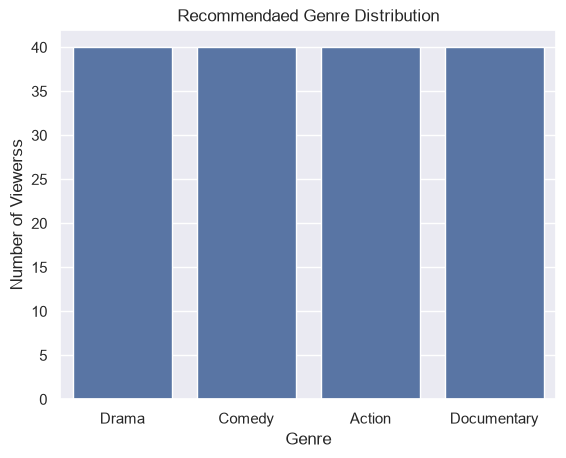

In [30]:
sns.countplot(data=df, x="Recommended_Genre")

plt.title("Recommendaed Genre Distribution")
plt.xlabel("Genre")
plt.ylabel("Number of Viewerss")
plt.show()

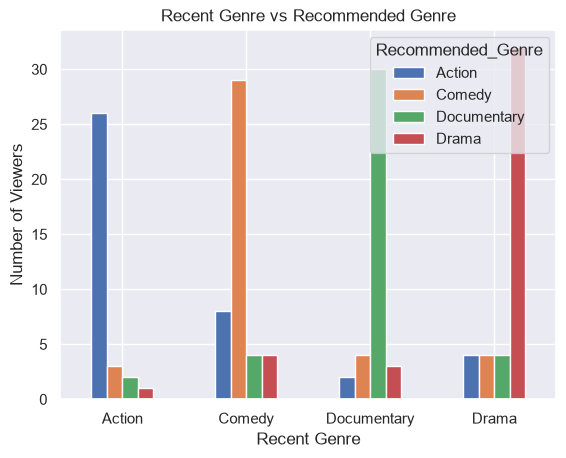

In [32]:
pd.crosstab(
    df["Recent_Genre"],
    df["Recommended_Genre"]
).plot(kind="bar")

plt.title("Recent Genre vs Recommended Genre")
plt.xlabel("Recent Genre")
plt.ylabel("Number of Viewers")
plt.xticks(rotation=0)
plt.show()

In [36]:
df.describe()
df[
    [
        "Average_Watch_Minutes",
        "Completion_Rate",
        "Action_Score",
        "Comedy_Score",
        "Drama_Score",
        "Documentary_Score"
    ]
].corr()

,Average_Watch_Minutes,Completion_Rate,Action_Score,Comedy_Score,Drama_Score,Documentary_Score
Average_Watch_Minutes,1.000000,0.064747,0.143753,-0.197893,0.262514,-0.174863
Completion_Rate,0.064747,1.000000,0.098751,-0.020441,0.216408,-0.195805
Action_Score,0.143753,0.098751,1.000000,-0.109272,-0.408039,-0.100771
Comedy_Score,-0.197893,-0.020441,-0.109272,1.000000,-0.141885,-0.306167
Drama_Score,0.262514,0.216408,-0.408039,-0.141885,1.000000,-0.207642
Documentary_Score,-0.174863,-0.195805,-0.100771,-0.306167,-0.207642,1.000000


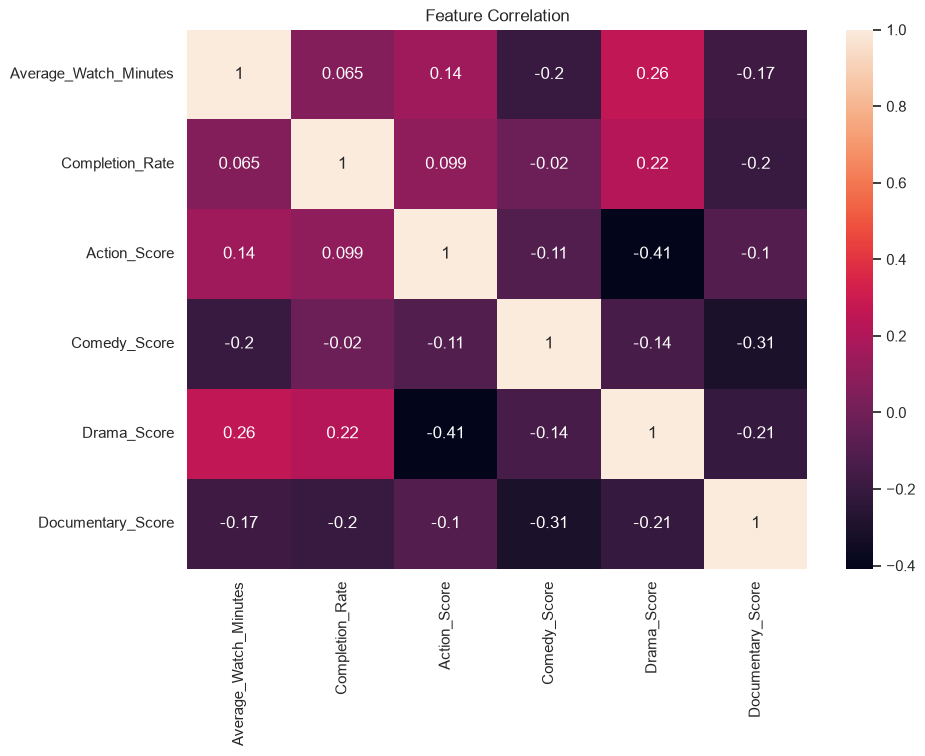

In [37]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[
        [
            "Average_Watch_Minutes",
            "Completion_Rate",
            "Action_Score",
            "Comedy_Score",
            "Drama_Score",
            "Documentary_Score"
        ]
    ].corr(),
    annot=True
)

plt.title("Feature Correlation")
plt.show()

In [39]:
pd.crosstab(
    df["Binge_Frequency"],
    df["Recommended_Genre"]
)

Recommended_Genre,Action,Comedy,Documentary,Drama
Binge_Frequency,,,,
High,21,10,5,24
Low,2,13,16,0
Medium,17,17,19,16


In [40]:
pd.crosstab(
    df["Age_Group"],
    df["Recommended_Genre"]
)

Recommended_Genre,Action,Comedy,Documentary,Drama
Age_Group,,,,
13-17,9,7,7,8
18-24,7,11,13,10
25-34,9,7,10,6
35-44,7,6,7,9
45+,8,9,3,7


In [41]:
pd.crosstab(
    df["Weekend_Viewer"],
    df["Recommended_Genre"]
)

Recommended_Genre,Action,Comedy,Documentary,Drama
Weekend_Viewer,,,,
No,13,12,19,19
Yes,27,28,21,21
